In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import D4CMPP_TLC
import SSC
from rdkit import Chem
import matplotlib.pyplot as plt

In [20]:
p=SSC.train(data='raw_DB', 
            molecule_columns=['Smiles','eluent1_smiles','eluent2_smiles',], 
            numeric_input_columns=['ratio1','ratio2'], 
            target=['Rf'],
            network='SSC_multi')

/opt/conda/lib/python3.10/site-packages/D4CMPP_TLC
Training from scratch to ./_Models/SSC_multi_raw_DB_Rf_620_20250918_110949
Sculptor Index: (6, 2, 0)
Device: cuda:0
#params: 172900
Train: 16119, Val: 2013, Test: 2014


Epoch 197:  10%|█████▎                                                | 197/2000 [53:59<8:14:11, 16.45s/it, train_loss=0.731, val_loss=0.755]


Forced termination
Loading params from ./_Models/SSC_multi_raw_DB_Rf_620_20250918_110949/param_0.7548508504345472.pth


Predicting: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 63/63 [00:11<00:00,  5.57it/s]


+--------+---------------------+---------------------+---------------------+
| target |       train_r2      |      train_mae      |      train_rmse     |
+--------+---------------------+---------------------+---------------------+
|   Rf   | 0.28631263971328735 | 0.10534799098968506 | 0.13157467544078827 |
+--------+---------------------+---------------------+---------------------+
+--------+--------------------+--------------------+--------------------+
| target |       val_r2       |      val_mae       |      val_rmse      |
+--------+--------------------+--------------------+--------------------+
|   Rf   | 0.2244998812675476 | 0.1081087738275528 | 0.1349368691444397 |
+--------+--------------------+--------------------+--------------------+
+--------+--------------------+---------------------+---------------------+
| target |      test_r2       |       test_mae      |      test_rmse      |
+--------+--------------------+---------------------+---------------------+
|   Rf   | 0.2005

founded model: ./_Models/SSC_multi_Rf&nat_Rf_620_20251013_054735
Device: cuda:0
#params: 2787460
Loading params from ./_Models/SSC_multi_Rf&nat_Rf_620_20251013_054735/final.pth
Sculptor Index: (6, 2, 0)


In [40]:
a_eq = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("SSC_multi_Rf&nat_Rf_620_20251007_141915")
a_sw = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("SSC_multi_SW_Rf&nat_Rf_620_20251004_165610")
a_full_eq = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("SSC_multi_Rf&nat_Rf_620_20251007_141710")
a_full_eq2 = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("SSC_multi_Rf&nat_Rf_620_20251013_054735")


founded model: ./_Models/SSC_multi_Rf&nat_Rf_620_20251007_141915
Device: cuda:1
#params: 2795780
Loading params from ./_Models/SSC_multi_Rf&nat_Rf_620_20251007_141915/final.pth
Sculptor Index: (6, 2, 0)
founded model: ./_Models/SSC_multi_SW_Rf&nat_Rf_620_20251004_165610
Device: cuda:0
#params: 1492674
Loading params from ./_Models/SSC_multi_SW_Rf&nat_Rf_620_20251004_165610/final.pth
Sculptor Index: (6, 2, 0)
founded model: ./_Models/SSC_multi_Rf&nat_Rf_620_20251007_141710
Device: cuda:1
#params: 2795780
Loading params from ./_Models/SSC_multi_Rf&nat_Rf_620_20251007_141710/final.pth
Sculptor Index: (6, 2, 0)


In [27]:
a_eq.get_score("Brc1cccc(N2CCCCC2)c1",
          "CCCCCC",
          "O=C(OCC)C",
          0.8,
          0.2,)

Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].


{'a0': array([[0.]], dtype=float32),
 'a1': array([[0.2906275]], dtype=float32),
 'b1': array([[0.4223767]], dtype=float32),
 'y': array([[0.308216]], dtype=float32)}

In [33]:
print(a.scaler.scaler.mean_, a.scaler.scaler.var_)

[0.44897715] [0.0452323]


In [38]:
"Cc1ccccc1/C(CN1C(=O)c2ccccc2C1=O)=C(\C=C\c1ccccc1)c1ccccc1"
"Brc1cccc(N2CCCCC2)c1"
"O=[N+]([O-])c1ccc(CBr)cc1"

array([[0.661656]])

In [72]:
l_eq, l_sw, l_full_eq = [], [], []
smi = "O=[N+]([O-])c1ccc(CBr)cc1"
for i in range(10):
    l_eq.append(
        a_eq.get_score(smi,
              "CCCCCC",
              "CCOC(C)=O",
              0.1*i,
              0.1*(10-i),)
    )
    l_sw.append(
        a_sw.get_score(smi,
              "CCCCCC",
              "CCOC(C)=O",
              0.1*i,
              0.1*(10-i),)
    )
    l_full_eq.append(
        a_full_eq2.get_score(smi,
              "CCCCCC",
              "CCOC(C)=O",
              0.1*i,
              0.1*(10-i),)
    )

Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].
Positional arguments are provided. Note that arguments should be in the orde

In [73]:
y_sw = a_sw.scaler.scaler.inverse_transform(np.concatenate([_['y'] for _ in l_sw]))
y_eq = a_eq.scaler.scaler.inverse_transform(np.concatenate([_['y'] for _ in l_eq]))
y_full_eq = a_full_eq2.scaler.scaler.inverse_transform(np.concatenate([_['y'] for _ in l_full_eq]))

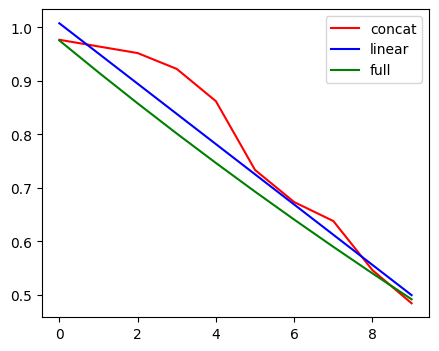

In [74]:
plt.figure(figsize=(5,4))
plt.plot(y_sw, 'r-', label = 'concat')
plt.plot(y_eq, 'b-', label = 'linear')
plt.plot(y_full_eq, 'g-', label= 'full')
plt.legend()

In [62]:
l_full_eq[0]

{'a0': array([[0.]], dtype=float32),
 'a1': array([[0.37605792]], dtype=float32),
 'b1': array([[0.45099527]], dtype=float32),
 'y': array([[0.45099527]], dtype=float32),
 'a3': array([[-4.206984]], dtype=float32),
 'b3': array([[-1.7956963]], dtype=float32),
 'd1': array([[16.15748]], dtype=float32)}